# Speed-only baselines, scored with TIMSE on the eval year

Four reference models that use **only** the hourly real-time ACE speed series pulled by
`python -m training.pull_ace_rtsw`. Every model is fitted on the training years only and scored by
`training.evaluate` on the held-out eval year, under the rules in `docs/evaluation.md`.

0. **Data and split.**
1. **Models**: what each baseline does.
2. **TIMSE**: pooled over the year and per forecast run, with the distribution of run scores.
3. **Predictions vs actuals**: scatter plots, error by lead and by observed speed, the TIMSE tail curve, and a fast-stream example.
4. **Residual analysis**: distribution, behaviour by lead, autocorrelation and drift.
5. **Findings and summary.**

Throughout, **residual = actual − forecast**, so a positive residual means the model under-predicted.
The headline scores can be reproduced without the notebook with `python -m training.run_baselines`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.tsa.stattools import acf

from training import run_baselines
from training.baselines import ALL
from training.datasets import DATA_DIR, EVAL_END, TRAIN_END, load_eval, load_hourly, load_train
from training.evaluate import HORIZON, run_forecasts, run_timse
from training.metrics import tail_mse_curve

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.precision", 1)
COLORS = dict(zip(ALL, ["tab:blue", "tab:orange", "tab:green", "tab:red"], strict=True))

## 0. Data and split

The split dates are pinned in `training.datasets`, so the eval year never moves. Missing hours are
left as NaN: they are never fed to a model as targets, and TIMSE skips them.

In [2]:
manifest = json.loads((DATA_DIR / "manifest.json").read_text())
series = load_hourly()
train, held_out = load_train(), load_eval()

pd.DataFrame(
    {
        "start": [train.index[0], held_out.index[0]],
        "end (exclusive)": [TRAIN_END, EVAL_END],
        "hours": [len(train), len(held_out)],
        "% missing": [100 * train.isna().mean(), 100 * held_out.isna().mean()],
        "median km/s": [train.median(), held_out.median()],
        "p99 km/s": [train.quantile(0.99), held_out.quantile(0.99)],
    },
    index=["train", "eval"],
)

,start,end (exclusive),hours,% missing,median km/s,p99 km/s
train,2021-10-20 00:00:00+00:00,2025-10-20 00:00:00+00:00,35064,6.0,421.6,721.0
eval,2025-10-20 00:00:00+00:00,2026-10-20 00:00:00+00:00,8760,1.3,446.2,758.6


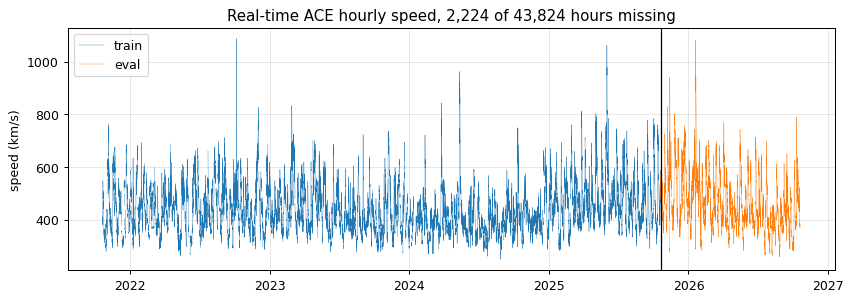

In [3]:
fig, ax = plt.subplots()
ax.plot(train.index, train, lw=0.3, color="tab:blue", label="train")
ax.plot(held_out.index, held_out, lw=0.3, color="tab:orange", label="eval")
ax.axvline(TRAIN_END, color="k", lw=1)
ax.set_ylabel("speed (km/s)")
missing, hours = manifest["missing_hours"], manifest["hours"]
ax.set_title(f"Real-time ACE hourly speed, {missing:,} of {hours:,} hours missing")
ax.legend(loc="upper left");

## 1. Models

All models are in `src/training/baselines.py`. The fitted models learn separate coefficients for
each lead hour k = 1…72, using every hour of the training years as a t0. A training sample is
dropped when its target is missing. Hyper-parameters are fixed and were not tuned on the eval year.

| Model | Forecast for t0 + k h |
|---|---|
| `persistence` | the last observed speed, for every k |
| `climatology_blend` | μ + wₖ·(last − μ). μ is the training mean; wₖ ∈ [0, 1] is fitted by least squares |
| `recurrence_27d` | aₖ + bₖ·last + cₖ·r. r is the mean speed within ±3 h of t0 + k − 27 days (one solar rotation); fitted by least squares |
| `autoregressive_48h` | Ridge regression (α = 1) on the last 48 hourly speeds |

**Missing inputs.** If no speed has been observed, `last` becomes μ. A recurrence window with no
data uses μ. A missing lag hour is replaced with `last`. These substitutions only affect the model
inputs; the stored data stays un-imputed.

## 2. TIMSE

`run_baselines.run()` passes each model through `training.evaluate.evaluate`. The harness fits the
model on the training years, then forecasts every 6-hourly t0 in the eval year from data observed by
t0. It reports two kinds of score:

- **Pooled TIMSE** (`timse`): every run's hours combined into one score for the year.
- **Per-run TIMSE** (`run_timse_*`): each 72-hour run scored on its own hours (its own thresholds),
  then summarised across runs. A run needs at least two observed hours to be scored.

Lower is better for both.

In [4]:
scores = run_baselines.run()
cols = [
    "model",
    "timse",
    "run_timse_mean",
    "run_timse_median",
    "run_timse_std",
    "run_timse_p10",
    "run_timse_p90",
    "run_timse_max",
    "rmse",
    "n_runs_scored",
]
table = scores[cols].set_index("model")
table.map(lambda x: f"{x:.3g}" if isinstance(x, float) else f"{x:,}")

  persistence          TIMSE 8.13e+07  run TIMSE median 7.756e+05  RMSE 110.0


  climatology_blend    TIMSE 9.855e+07  run TIMSE median 4.317e+05  RMSE 91.9


  recurrence_27d       TIMSE 8.397e+07  run TIMSE median 4.109e+05  RMSE 84.4


  autoregressive_48h   TIMSE 1.043e+08  run TIMSE median 4.336e+05  RMSE 91.4


,timse,run_timse_mean,run_timse_median,run_timse_std,run_timse_p10,run_timse_p90,run_timse_max,rmse,n_runs_scored
model,,,,,,,,,
persistence,8.13e+07,5.57e+06,7.76e+05,1.64e+07,8.33e+04,1.38e+07,2.84e+08,110,"1,448"
recurrence_27d,8.4e+07,4.29e+06,4.11e+05,1.48e+07,6.09e+04,8.52e+06,2.26e+08,84.4,"1,448"
climatology_blend,9.85e+07,5.09e+06,4.32e+05,1.68e+07,6.87e+04,1.1e+07,2.47e+08,91.9,"1,448"
autoregressive_48h,1.04e+08,5.2e+06,4.34e+05,1.8e+07,6.59e+04,1.06e+07,2.78e+08,91.4,"1,448"


The cell below keeps every run's forecasts and actuals for the rest of the notebook.
`run_forecasts` is the same protocol the harness uses: fit on the training years only, then predict
each eval t0 from the hours before it.

In [5]:
runs = {name: run_forecasts(cls()) for name, cls in ALL.items()}
t0s, _, actual = runs["persistence"]
forecasts = {name: f for name, (_, f, _) in runs.items()}
residuals = {name: actual - f for name, f in forecasts.items()}
run_scores = pd.DataFrame({name: run_timse(f, actual) for name, f in forecasts.items()}, index=t0s)

print(
    f"{len(t0s)} runs x {HORIZON} leads; {np.isnan(actual).sum()} actuals missing; "
    f"{run_scores.isna().any(axis=1).sum()} runs unscored"
)

1448 runs x 72 leads; 1344 actuals missing; 0 runs unscored


### 2.1 Distribution of per-run TIMSE

Per-run TIMSE is heavily right-skewed: most runs are quiet, and a few runs that meet a fast stream
score orders of magnitude worse. The histograms therefore use a log scale.

In [6]:
summary = run_scores.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).T
summary["skew"] = run_scores.skew()
summary["share of total from top 5% runs"] = [
    s.nlargest(int(0.05 * s.count())).sum() / s.sum() for _, s in run_scores.items()
]
summary["count"] = summary["count"].astype(int)
summary.map(lambda x: f"{x:.3g}" if isinstance(x, float) else f"{x:,}")

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max,skew,share of total from top 5% runs
persistence,"1,448",5.57e+06,1.64e+07,9.39e+03,8.33e+04,2.43e+05,7.76e+05,4.31e+06,1.38e+07,5.68e+07,2.84e+08,9.43,0.499
climatology_blend,"1,448",5.09e+06,1.68e+07,9.92e+03,6.87e+04,1.53e+05,4.32e+05,3.4e+06,1.1e+07,8.73e+07,2.47e+08,8.08,0.565
recurrence_27d,"1,448",4.29e+06,1.48e+07,8.66e+03,6.09e+04,1.43e+05,4.11e+05,2.3e+06,8.52e+06,8.61e+07,2.26e+08,8.01,0.612
autoregressive_48h,"1,448",5.2e+06,1.8e+07,9.4e+03,6.59e+04,1.45e+05,4.34e+05,3.46e+06,1.06e+07,9.36e+07,2.78e+08,8.55,0.579


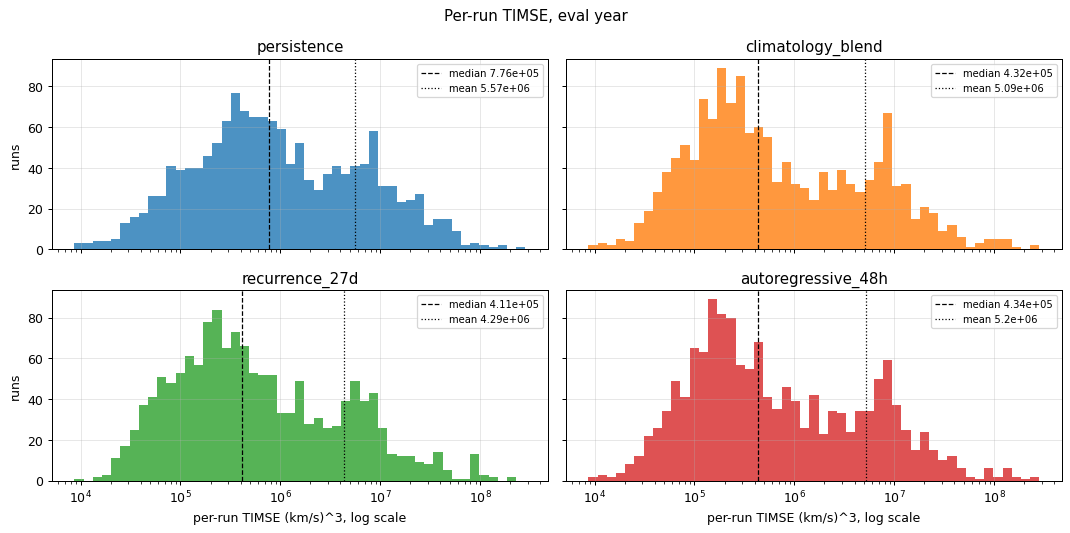

In [7]:
bins = np.logspace(np.log10(run_scores.min().min()), np.log10(run_scores.max().max()), 50)
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, name in zip(axes.flat, ALL, strict=True):
    s = run_scores[name].dropna()
    ax.hist(s, bins=bins, color=COLORS[name], alpha=0.8)
    ax.axvline(s.median(), color="k", ls="--", lw=1, label=f"median {s.median():.3g}")
    ax.axvline(s.mean(), color="k", ls=":", lw=1, label=f"mean {s.mean():.3g}")
    ax.set_xscale("log")
    ax.set_title(name)
    ax.legend(fontsize=8)
for ax in axes[1]:
    ax.set_xlabel("per-run TIMSE (km/s)^3, log scale")
for ax in axes[:, 0]:
    ax.set_ylabel("runs")
fig.suptitle("Per-run TIMSE, eval year")
fig.tight_layout()

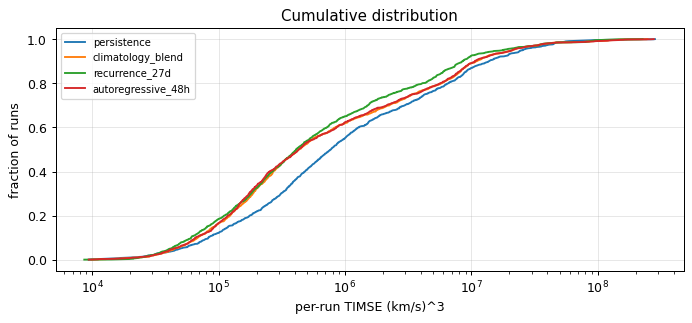

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for name in ALL:
    s = np.sort(run_scores[name].dropna())
    ax.plot(s, np.arange(1, len(s) + 1) / len(s), color=COLORS[name], label=name)
ax.set_xscale("log")
ax.set(xlabel="per-run TIMSE (km/s)^3", ylabel="fraction of runs", title="Cumulative distribution")
ax.legend(fontsize=8);

### 2.2 Which runs win?

Head-to-head, per run: the share of runs where each model beats persistence, and the per-run
scores over the eval year. Bad runs cluster around fast-stream arrivals.

,runs beating persistence,median ratio to persistence
climatology_blend,0.64,0.80
recurrence_27d,0.70,0.64
autoregressive_48h,0.65,0.77


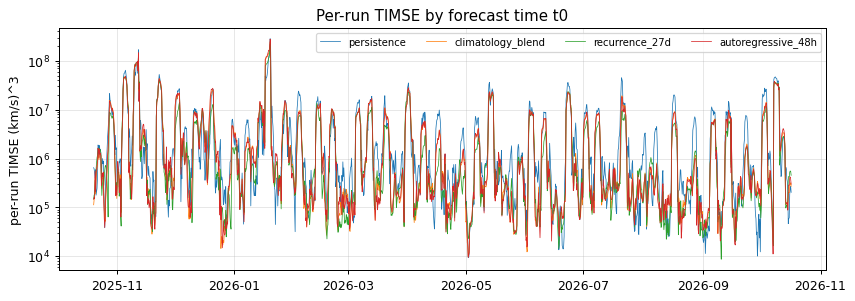

In [9]:
versus = pd.DataFrame(
    {
        name: {
            "runs beating persistence": (run_scores[name] < run_scores["persistence"]).mean(),
            "median ratio to persistence": (run_scores[name] / run_scores["persistence"]).median(),
        }
        for name in ALL
        if name != "persistence"
    }
).T
display(versus.map("{:.2f}".format))

fig, ax = plt.subplots()
for name in ALL:
    ax.plot(run_scores.index, run_scores[name], lw=0.6, color=COLORS[name], label=name)
ax.set_yscale("log")
ax.set(ylabel="per-run TIMSE (km/s)^3", title="Per-run TIMSE by forecast time t0")
ax.legend(fontsize=8, ncol=4);

## 3. Predictions vs actuals

### 3.1 Scatter plots

Every scored hour of every run (about 103,000 points per model). On the left, a perfect forecast
lies on the diagonal. On the right, a perfect forecast lies on zero; points above zero are
under-predictions.

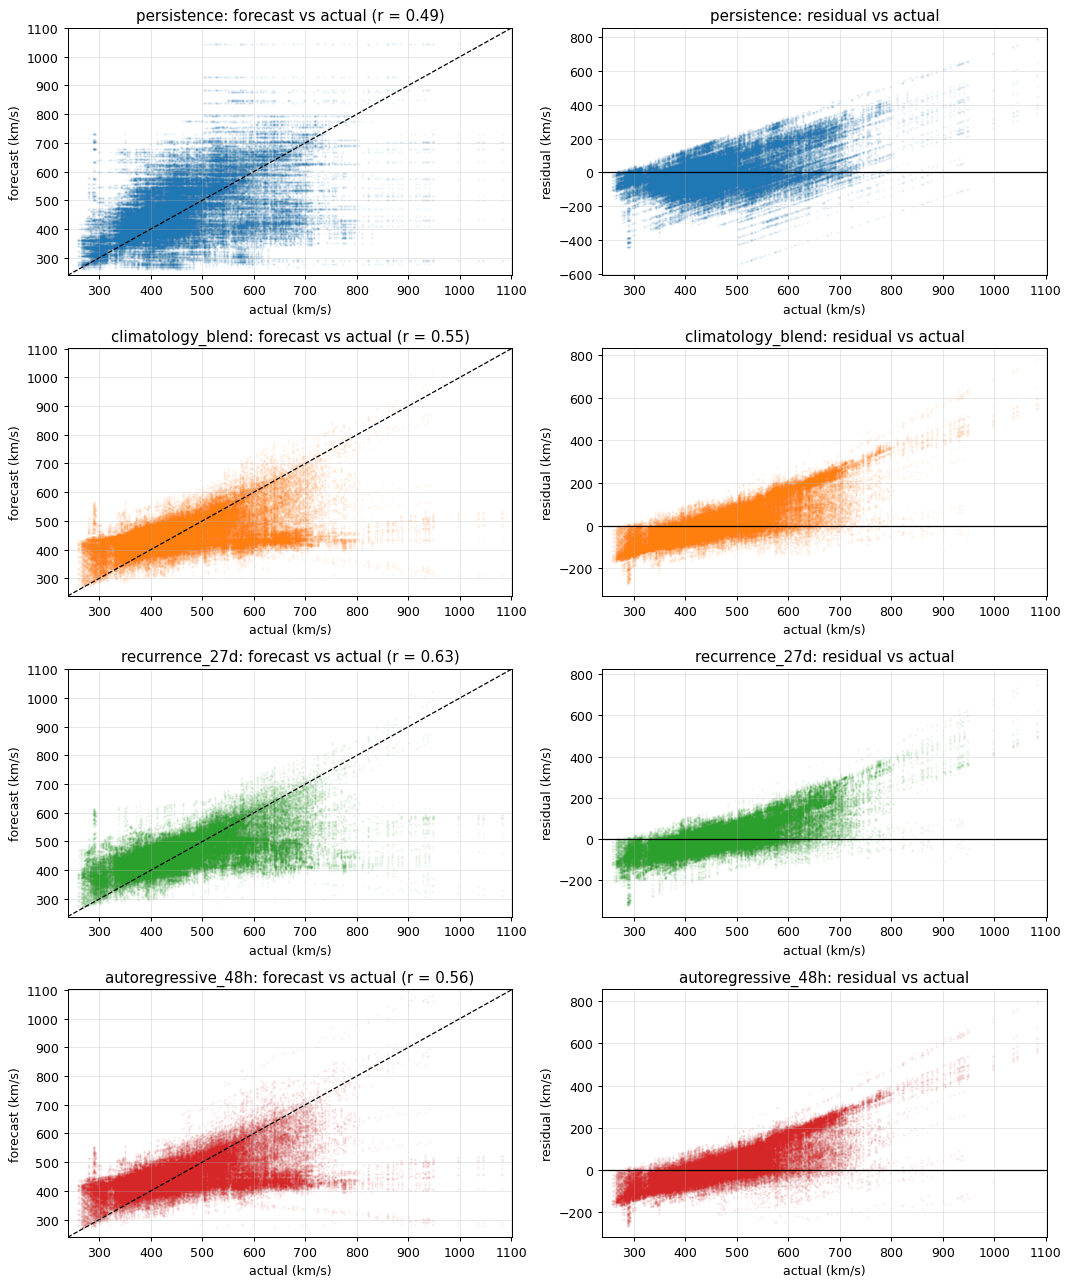

In [10]:
ok = np.isfinite(actual)
fig, axes = plt.subplots(len(ALL), 2, figsize=(12, 3.6 * len(ALL)))
lims = (np.nanmin(actual) - 20, np.nanmax(actual) + 20)
for (ax_l, ax_r), name in zip(axes, ALL, strict=True):
    a, f, r = actual[ok], forecasts[name][ok], residuals[name][ok]
    ax_l.scatter(a, f, s=1, alpha=0.05, color=COLORS[name], rasterized=True)
    ax_l.plot(lims, lims, "k--", lw=1)
    ax_l.set(xlim=lims, ylim=lims, xlabel="actual (km/s)", ylabel="forecast (km/s)")
    ax_l.set_title(f"{name}: forecast vs actual (r = {np.corrcoef(a, f)[0, 1]:.2f})")
    ax_r.scatter(a, r, s=1, alpha=0.05, color=COLORS[name], rasterized=True)
    ax_r.axhline(0, color="k", lw=1)
    ax_r.set(xlim=lims, xlabel="actual (km/s)", ylabel="residual (km/s)")
    ax_r.set_title(f"{name}: residual vs actual")
fig.tight_layout()

### 3.2 Error by lead time

All models start at about 22 km/s at 1 h. Persistence degrades fastest, and recurrence holds up
best at long leads.

lead (h),1,6,24,48,72
persistence,21.7,47.7,94.8,127.7,143.4
climatology_blend,21.6,46.6,86.0,105.3,110.6
recurrence_27d,21.5,46.1,81.7,95.4,98.3
autoregressive_48h,21.5,46.2,85.0,104.9,110.7


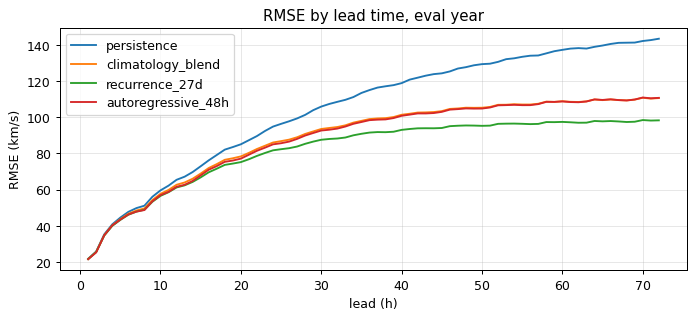

In [11]:
lead_index = pd.RangeIndex(1, HORIZON + 1, name="lead (h)")
lead_rmse = pd.DataFrame(
    {name: np.sqrt(np.nanmean(r**2, axis=0)) for name, r in residuals.items()}, index=lead_index
)
ax = lead_rmse.plot(figsize=(9, 3.5), color=COLORS)
ax.set_ylabel("RMSE (km/s)")
ax.set_title("RMSE by lead time, eval year")
lead_rmse.loc[[1, 6, 24, 48, 72]].T

### 3.3 Error by observed speed

Mean residual and RMSE in bands of the observed speed. Every model over-predicts slow wind
(negative residual) and under-predicts fast wind (positive residual).

In [12]:
bands = [(0, 450), (450, 600), (600, 700), (700, 2000)]


def band_label(lo, hi):
    return f"{lo}-{hi}" if hi < 2000 else f">={lo}"


rows = {}
for name, r in residuals.items():
    row = {}
    for lo, hi in bands:
        sel = (actual >= lo) & (actual < hi)
        row[(band_label(lo, hi), "mean residual")] = r[sel].mean()
        row[(band_label(lo, hi), "rmse")] = np.sqrt((r[sel] ** 2).mean())
    rows[name] = row
by_speed = pd.DataFrame(rows).T
by_speed.columns = pd.MultiIndex.from_tuples(by_speed.columns)
print(
    "points per band:",
    {band_label(lo, hi): int(((actual >= lo) & (actual < hi)).sum()) for lo, hi in bands},
)
by_speed

points per band: {'0-450': 53190, '450-600': 36282, '600-700': 10764, '>=700': 2676}


0-450             450-600              600-700  \
                   mean residual  rmse mean residual   rmse mean residual   
persistence                -37.0  81.0           9.2  108.1         100.7   
climatology_blend          -39.6  59.5          38.1   71.6         136.9   
recurrence_27d             -38.5  60.2          25.7   61.9         116.7   
autoregressive_48h         -37.2  57.0          38.6   71.7         134.8   

                                  >=700         
                     rmse mean residual   rmse  
persistence         161.9         200.8  266.3  
climatology_blend   162.0         241.5  281.8  
recurrence_27d      142.7         218.2  260.3  
autoregressive_48h  161.6         240.4  286.3

### 3.4 Why pooled TIMSE ranks the models differently from RMSE

TIMSE = Σⱼ (v*ⱼ₊₁ − v*ⱼ)·Mⱼ, where Mⱼ is the mean squared error over the hours with an observed speed
≥ v*ⱼ. In other words, TIMSE is the area under the tail-MSE curve M(v) plotted against the threshold v.
Each km/s of threshold counts equally, whether a threshold has many hours above it or only a few. The
long, sparsely populated fast tail (600 → 900+ km/s) therefore contributes a large share of the area.
`training.metrics.tail_mse_curve` returns exactly the curve that `timse` integrates.

share of scored points:

 {'>= 600': '13.06%', '>= 800': '0.51%', '>= 900': '0.23%'}


,thresholds 0-600,thresholds 600-800,thresholds 800-900,thresholds 900-2000,TIMSE
persistence,6.44e+06,1.63e+07,1.56e+07,4.29e+07,8.13e+07
climatology_blend,5.3e+06,1.82e+07,1.92e+07,5.58e+07,9.85e+07
recurrence_27d,4.26e+06,1.59e+07,1.65e+07,4.73e+07,8.4e+07
autoregressive_48h,5.33e+06,1.9e+07,2.06e+07,5.94e+07,1.04e+08


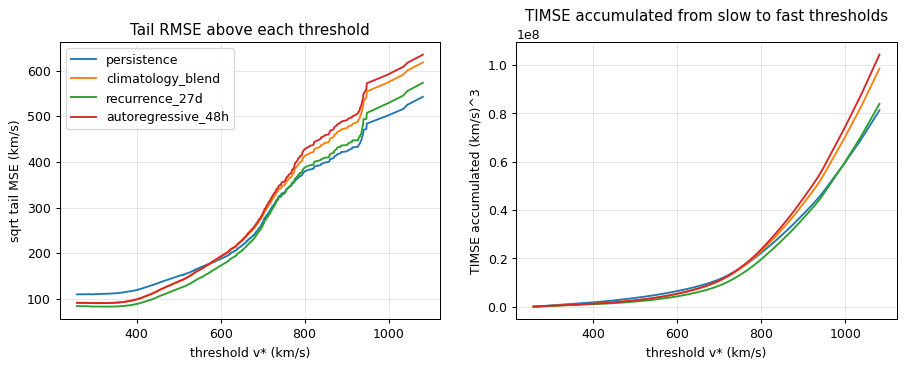

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split = {}
for name, f in forecasts.items():
    v, m = tail_mse_curve(actual, f)  # the same curve training.metrics.timse integrates
    contrib = np.diff(v) * m[:-1]  # TIMSE contribution of each threshold gap
    axes[0].plot(v, np.sqrt(m), color=COLORS[name], label=name)
    axes[1].plot(v[1:], np.cumsum(contrib), color=COLORS[name], label=name)
    split[name] = {
        f"thresholds {lo}-{hi}": contrib[(v[:-1] >= lo) & (v[:-1] < hi)].sum()
        for lo, hi in [(0, 600), (600, 800), (800, 900), (900, 2000)]
    }
    split[name]["TIMSE"] = contrib.sum()
axes[0].set(xlabel="threshold v* (km/s)", ylabel="sqrt tail MSE (km/s)")
axes[0].set_title("Tail RMSE above each threshold")
axes[1].set(xlabel="threshold v* (km/s)", ylabel="TIMSE accumulated (km/s)^3")
axes[1].set_title("TIMSE accumulated from slow to fast thresholds")
axes[0].legend()

observed = actual[np.isfinite(actual)]
print(
    "share of scored points:", {f">= {v}": f"{(observed >= v).mean():.2%}" for v in (600, 800, 900)}
)
pd.DataFrame(split).T.map("{:.3g}".format)

### 3.5 A fast-stream example

The 48-hour-ahead forecasts around the fastest wind in the eval year. Each point is the forecast made
48 h earlier for that hour.

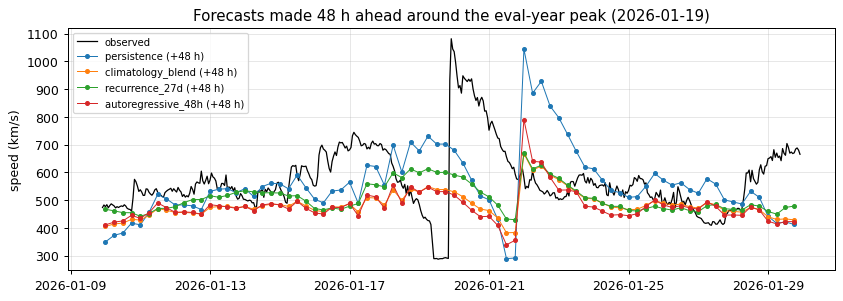

In [14]:
lead = 48
target_times = t0s + pd.Timedelta(hours=lead)
peak = held_out.idxmax()
start, end = peak - pd.Timedelta(days=10), peak + pd.Timedelta(days=10)
window = (target_times >= start) & (target_times <= end)

fig, ax = plt.subplots()
obs = series[start:end]
ax.plot(obs.index, obs, color="k", lw=1, label="observed")
for name, f in forecasts.items():
    label = f"{name} (+{lead} h)"
    ax.plot(
        target_times[window],
        f[window, lead - 1],
        marker=".",
        lw=0.8,
        color=COLORS[name],
        label=label,
    )
ax.set_ylabel("speed (km/s)")
ax.set_title(f"Forecasts made {lead} h ahead around the eval-year peak ({peak:%Y-%m-%d})")
ax.legend(fontsize=8, loc="upper left");

## 4. Residual analysis

### 4.1 Distribution

A well-behaved forecast has residuals centred on zero and roughly symmetric. Positive skew means
large under-predictions (missed fast streams) are more common than large over-predictions.

,mean,median,std,skew,excess kurtosis,p1,p5,p95,p99,share > +200,share < -200
persistence,-0.13,-13.75,109.99,0.70,1.99,-244.74,-153.91,210.03,310.20,0.06,0.02
climatology_blend,13.54,-6.36,90.88,1.36,3.19,-138.24,-97.59,198.60,292.78,0.05,0.00
recurrence_27d,7.04,-8.48,84.06,1.36,4.13,-149.04,-98.17,171.64,279.71,0.03,0.00
autoregressive_48h,14.72,-4.56,90.21,1.44,3.81,-136.42,-95.74,196.48,297.53,0.05,0.00


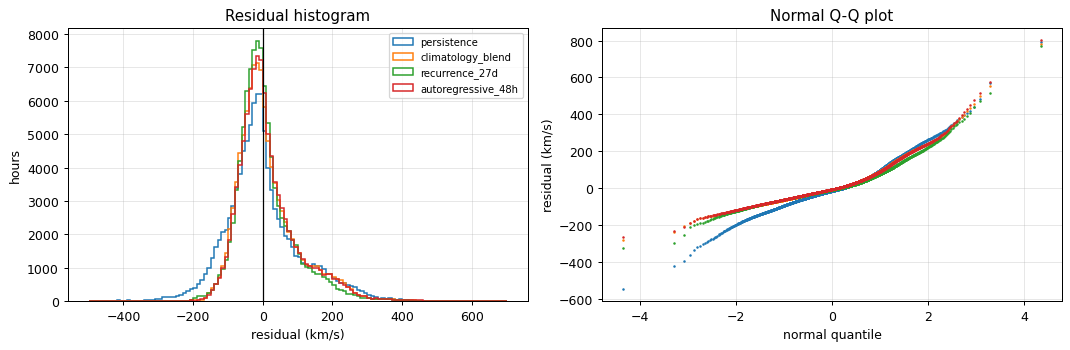

In [15]:
def residual_stats(r):
    r = r[np.isfinite(r)]
    return {
        "mean": r.mean(),
        "median": np.median(r),
        "std": r.std(),
        "skew": stats.skew(r),
        "excess kurtosis": stats.kurtosis(r),
        "p1": np.percentile(r, 1),
        "p5": np.percentile(r, 5),
        "p95": np.percentile(r, 95),
        "p99": np.percentile(r, 99),
        "share > +200": (r > 200).mean(),
        "share < -200": (r < -200).mean(),
    }


residual_table = pd.DataFrame({n: residual_stats(r.ravel()) for n, r in residuals.items()}).T
display(residual_table.map("{:.2f}".format))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
edges = np.arange(-500, 701, 10)
for name, r in residuals.items():
    r = r[np.isfinite(r)]
    axes[0].hist(r, bins=edges, histtype="step", lw=1.2, color=COLORS[name], label=name)
    (osm, osr), _ = stats.probplot(r, dist="norm")
    keep = np.linspace(0, len(osm) - 1, 2000).astype(int)
    axes[1].plot(osm[keep], osr[keep], ".", ms=2, color=COLORS[name], label=name)
axes[0].axvline(0, color="k", lw=1)
axes[0].set(xlabel="residual (km/s)", ylabel="hours", title="Residual histogram")
axes[0].legend(fontsize=8)
axes[1].set(xlabel="normal quantile", ylabel="residual (km/s)", title="Normal Q-Q plot")
fig.tight_layout()

### 4.2 By lead time

The mean residual shows whether bias builds up with lead; the spread shows how fast uncertainty
grows.

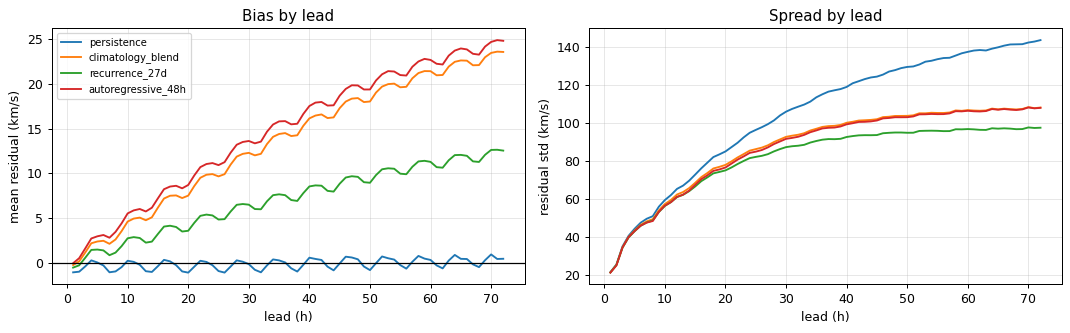

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, r in residuals.items():
    axes[0].plot(lead_index, np.nanmean(r, axis=0), color=COLORS[name], label=name)
    axes[1].plot(lead_index, np.nanstd(r, axis=0), color=COLORS[name], label=name)
axes[0].axhline(0, color="k", lw=1)
axes[0].set(xlabel="lead (h)", ylabel="mean residual (km/s)", title="Bias by lead")
axes[1].set(xlabel="lead (h)", ylabel="residual std (km/s)", title="Spread by lead")
axes[0].legend(fontsize=8)
fig.tight_layout()

### 4.3 Autocorrelation over time

The 24-hour-ahead residual as a series over forecast times (one value every 6 h). Correlation
between successive runs is expected, since neighbouring runs forecast overlapping hours. A peak near
27 days would mean the model leaves solar-rotation structure in its errors.

,1 d,3 d,7 d,14 d,27 d
persistence,-0.05,-0.10,-0.00,-0.09,0.21
climatology_blend,0.08,-0.06,0.02,-0.09,0.25
recurrence_27d,0.04,-0.05,0.00,-0.08,0.09
autoregressive_48h,-0.01,0.02,0.02,-0.07,0.22


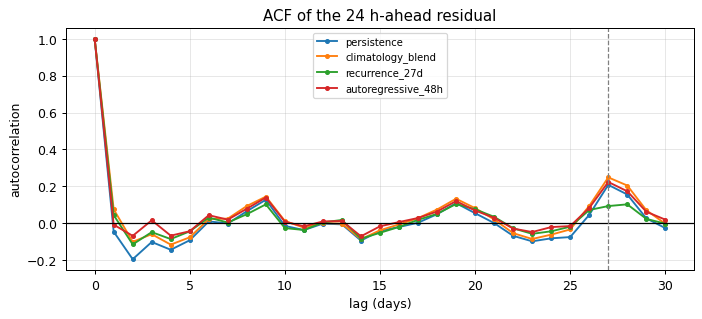

In [17]:
lag_days = np.arange(0, 31)
steps = lag_days * 4  # runs are 6 h apart
fig, ax = plt.subplots(figsize=(9, 3.5))
acf_at = {}
for name, r in residuals.items():
    s = pd.Series(r[:, 23], index=t0s)
    c = acf(s.to_numpy(), nlags=steps[-1], missing="conservative")
    ax.plot(lag_days, c[steps], marker=".", color=COLORS[name], label=name)
    acf_at[name] = {f"{d} d": c[d * 4] for d in (1, 3, 7, 14, 27)}
ax.axhline(0, color="k", lw=1)
ax.axvline(27, color="grey", ls="--", lw=1)
ax.set(xlabel="lag (days)", ylabel="autocorrelation", title="ACF of the 24 h-ahead residual")
ax.legend(fontsize=8)
pd.DataFrame(acf_at).T.map("{:.2f}".format)

### 4.4 Drift over the eval year

The 27-day rolling mean of the 24-hour-ahead residual. Long stretches away from zero point to
regime changes that the training years didn't cover.

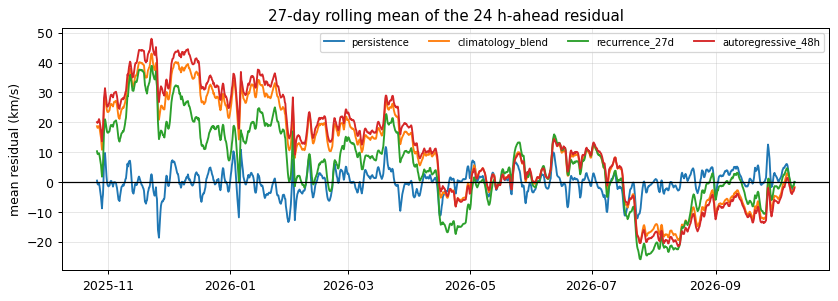

In [18]:
fig, ax = plt.subplots()
for name, r in residuals.items():
    s = pd.Series(r[:, 23], index=t0s)
    ax.plot(
        s.index,
        s.rolling(27 * 4, center=True, min_periods=20 * 4).mean(),
        color=COLORS[name],
        label=name,
    )
ax.axhline(0, color="k", lw=1)
ax.set(ylabel="mean residual (km/s)", title="27-day rolling mean of the 24 h-ahead residual")
ax.legend(fontsize=8, ncol=4);

## 5. Findings

Eval year: 2025-10-20 → 2026-10-20. 1,448 forecast runs, all scorable; 102,912 hourly points scored and 1,344 skipped because the actual was missing.

### (i) Pooled and per-run TIMSE disagree about the winner
| Model | pooled TIMSE | per-run mean | per-run median | runs beating persistence |
|---|---|---|---|---|
| persistence | **8.13 × 10⁷** | 5.57 × 10⁶ | 7.76 × 10⁵ | — |
| recurrence_27d | 8.40 × 10⁷ | **4.29 × 10⁶** | **4.11 × 10⁵** | **70%** |
| climatology_blend | 9.85 × 10⁷ | 5.09 × 10⁶ | 4.32 × 10⁵ | 64% |
| autoregressive_48h | 10.43 × 10⁷ | 5.20 × 10⁶ | 4.34 × 10⁵ | 65% |

- **Pooled, persistence wins narrowly. Run by run, it comes last on the median.** Recurrence has the lowest per-run mean and median and beats persistence in 70% of runs. Its median run scores 0.64× persistence's.
- **The two views differ because pooled TIMSE builds its thresholds from the whole year.** The few hours above 900 km/s (0.23% of points, from two events: 2025-11-13 and 2026-01-19/20) set a long threshold range that only those events reach. They contribute 53% of persistence's pooled TIMSE. In per-run TIMSE, each run's thresholds come from its own 72 hours, so one event only dominates the runs that contain it.
- **Benchlab hasn't said which aggregation the leaderboard uses.** Until it does, a model should be judged on both views.

### (ii) The per-run distribution is heavy-tailed
- **Per-run TIMSE spans four orders of magnitude**, from about 10⁴ to 3 × 10⁸, with skew 8–9.
- **The worst runs carry the total.** The worst 5% of runs hold 50–61% of each model's per-run total.
- **On a log scale the histograms are bimodal.** Most runs are quiet (10⁵–10⁶), and a second group of runs that meet a fast stream sits around 10⁷.
- **Recurrence moves runs out of the bad group.** It has the lowest 75th and 90th percentiles (2.3 × 10⁶ and 8.5 × 10⁶).
- **The bad runs line up across models.** The per-run timeline shows the same spikes for every model, because they come from the same fast-stream arrivals.

### (iii) Predictions vs actuals
- **The fitted models are pulled toward the mean.** They rarely forecast above about 700 km/s. Their residuals rise almost linearly with the actual speed: −38 km/s on average below 450 km/s, +218 to +242 km/s above 700 km/s. Recurrence has the highest correlation with the actuals (r = 0.63).
- **Persistence keeps the right spread but is often wrong in time.** Its forecasts are flat lines within a run, which show as horizontal stripes in the scatter plot. Its forecast-vs-actual correlation is the lowest (r = 0.49), and its RMSE grows fastest with lead (143 km/s at 72 h, against 98 for recurrence).

### (iv) Residuals
- **The distribution is skewed toward under-prediction.**
  - The fitted models have skew 1.4 and excess kurtosis 3–4, so big misses are mostly missed fast streams.
  - Persistence is more symmetric (skew 0.7) but wider (std 110 against 84–91 km/s).
  - Recurrence has the fewest large under-predictions: 3% of hours more than 200 km/s too low, against 5–6% for the others.
- **The fitted models' bias grows with lead.** It reaches +12 km/s (recurrence) to +25 km/s (autoregressive) at 72 h, while persistence stays at 0. The training years were slower than the eval year (median 422 against 446 km/s), so models that drift back toward the training mean under-predict.
- **That bias also changes with the season.** The 27-day rolling bias of the fitted models is +20 to +45 km/s in November–February and −10 to −25 km/s in July–August. The solar-wind regime shifted during the eval year, and fixed coefficients can't follow it.
- **Rotation structure is left in the errors.** The 24 h-ahead residual autocorrelates at 27 days (0.21–0.25) for persistence, climatology and autoregressive. Recurrence removes most of it (0.09). Smaller bumps near 9 and 19 days hint at several streams per rotation.
- **Sudden jumps can't be predicted from speed alone.** The 2026-01-19 jump from about 300 to 1,080 km/s was missed by every model. The dip to about 290 km/s just before it may be an artefact in the real-time data, but it is still the series the live leaderboard scores.

## 6. Summary

**Bottom line:** recurrence is the strongest speed-only baseline. It has the best per-run TIMSE, the best RMSE, the fewest large misses and the least leftover rotation structure. Persistence wins only on pooled TIMSE, and only because of two extreme events. Every baseline under-predicts fast wind and misses sudden jumps.

| Area | Outcome | What it means for the next model |
|---|---|---|
| **Scoring** | Pooled TIMSE: persistence ranks first. Per-run TIMSE: recurrence ranks first, persistence last on the median. | Report both until Benchlab confirms how it aggregates. Treat a pooled TIMSE lead built on a couple of events with caution. |
| **Heavy tail** | The worst 5% of runs hold 50–61% of the per-run total. Those runs are fast-stream arrivals. | Gains come from the bad runs: forecasting fast-stream onsets and speed levels. |
| **Shrinkage** | Fitted models under-predict above 700 km/s by 218–242 km/s, and their forecasts rarely exceed about 700 km/s. | Use a tail-weighted (TIMSE-like) loss, or blend in persistence, to keep fast forecasts fast. |
| **Bias and drift** | Bias grows to +12 to +25 km/s by 72 h and swings with the season (+45 to −25 km/s). | Fit on recent data, or let the level adapt (e.g. an online bias correction from recent residuals). |
| **Rotation** | Recurrence removes most of the 27-day residual structure. | Keep the recurrence input. Consider sub-rotation lags (about 9 and 13.5 days). |
| **Extremes** | CME-like jumps are missed by every model. | Add solar inputs (coronal holes, CME alerts). Speed history alone has a ceiling. |
